## импорты

In [18]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

random_state = 42
sns.set_theme(style="whitegrid")

## EDA

In [19]:
data_path = Path("data/ObesityDataSet_raw_and_data_sinthetic.csv")
target_column = "NObeyesdad"

if not data_path.exists():
    raise FileNotFoundError(
        f"Place the dataset CSV at {data_path} before running this notebook."
    )

dataset = pd.read_csv(data_path)

print(f"Rows: {dataset.shape[0]}, columns: {dataset.shape[1]}")
display(dataset.head())
dataset.info()
display(dataset.isna().sum().sort_values(ascending=False).to_frame("missing_values"))
display(dataset.describe(include="all").T)

Rows: 2111, columns: 17


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


<class 'pandas.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   str    
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   str    
 5   FAVC                            2111 non-null   str    
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   str    
 9   SMOKE                           2111 non-null   str    
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   str    
 12  FAF                             2111 non-null

,missing_values
Gender,0
Age,0
Height,0
Weight,0
family_history_with_overweight,0
FAVC,0
FCVC,0
NCP,0
CAEC,0
SMOKE,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Gender,2111,2,Male,1068,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,2111.0,NaN,NaN,NaN,24.3126,6.345968,14.0,19.947192,22.77789,26.0,61.0
Height,2111.0,NaN,NaN,NaN,1.701677,0.093305,1.45,1.63,1.700499,1.768464,1.98
Weight,2111.0,NaN,NaN,NaN,86.586058,26.191172,39.0,65.473343,83.0,107.430682,173.0
family_history_with_overweight,2111,2,yes,1726,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FAVC,2111,2,yes,1866,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FCVC,2111.0,NaN,NaN,NaN,2.419043,0.533927,1.0,2.0,2.385502,3.0,3.0
NCP,2111.0,NaN,NaN,NaN,2.685628,0.778039,1.0,2.658738,3.0,3.0,4.0
CAEC,2111,4,Sometimes,1765,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SMOKE,2111,2,no,2067,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## предобработка

In [20]:
features = dataset.drop(columns=target_column)
target = dataset[target_column]

numeric_columns = features.select_dtypes(include="number").columns.tolist()
categorical_columns = features.select_dtypes(exclude="number").columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    features,
    target,
    test_size=0.2,
    random_state=random_state,
    stratify=target,
)

numeric_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
categorical_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, numeric_columns),
        ("categorical", categorical_preprocessor, categorical_columns),
    ]
)

print(f"Training rows: {len(X_train)}")
print(f"Test rows: {len(X_test)}")
print(f"Numeric features: {len(numeric_columns)}")
print(f"Categorical features: {len(categorical_columns)}")

Training rows: 1688
Test rows: 423
Numeric features: 8
Categorical features: 8


## стат. анализ и сравнение моделей

In [21]:
cross_validation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=random_state,
)

models = {
    "logistic_regression": Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", LogisticRegression(max_iter=2000)),
        ]
    ),
    "decision_tree": Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", DecisionTreeClassifier(random_state=random_state)),
        ]
    ),
    "random_forest": Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            (
                "classifier",
                RandomForestClassifier(random_state=random_state, n_jobs=-1),
            ),
        ]
    ),
    "svc": Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", SVC()),
        ]
    ),
}

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
}

comparison_rows = []
for model_name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cross_validation,
        scoring=scoring,
        return_train_score=True,
    )
    comparison_rows.append(
        {
            "model": model_name,
            "cv_accuracy": scores["test_accuracy"].mean(),
            "cv_macro_f1": scores["test_macro_f1"].mean(),
            "cv_balanced_accuracy": scores["test_balanced_accuracy"].mean(),
            "train_macro_f1": scores["train_macro_f1"].mean(),
        }
    )

comparison = pd.DataFrame(comparison_rows).set_index("model")
display(comparison.sort_values("cv_macro_f1", ascending=False).round(3))

,cv_accuracy,cv_macro_f1,cv_balanced_accuracy,train_macro_f1
model,,,,
random_forest,0.932,0.930,0.930,1.000
decision_tree,0.925,0.922,0.923,1.000
svc,0.913,0.910,0.911,0.960
logistic_regression,0.873,0.868,0.871,0.895


In [22]:
random_forest_search = GridSearchCV(
    estimator=models["random_forest"],
    param_grid={
        "classifier__n_estimators": [150, 300],
        "classifier__max_depth": [None, 10, 20],
        "classifier__min_samples_leaf": [1, 2],
    },
    scoring="f1_macro",
    cv=cross_validation,
    n_jobs=-1,
)
random_forest_search.fit(X_train, y_train)

print(f"Best parameters: {random_forest_search.best_params_}")
print(f"Best cross-validation macro F1: {random_forest_search.best_score_:.3f}")

best_model = random_forest_search.best_estimator_
test_predictions = best_model.predict(X_test)

test_metrics = pd.Series(
    {
        "accuracy": accuracy_score(y_test, test_predictions),
        "macro_f1": f1_score(y_test, test_predictions, average="macro"),
        "balanced_accuracy": balanced_accuracy_score(y_test, test_predictions),
    },
    name="test_score",
)
display(test_metrics.to_frame().round(3))

test_report = pd.DataFrame(
    classification_report(
        y_test,
        test_predictions,
        output_dict=True,
        zero_division=0,
    )
).T
display(test_report.round(3))

Best parameters: {'classifier__max_depth': 20, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 300}
Best cross-validation macro F1: 0.933


,test_score
accuracy,0.939
macro_f1,0.938
balanced_accuracy,0.937


,precision,recall,f1-score,support
Insufficient_Weight,1.000,0.944,0.971,54.000
Normal_Weight,0.779,0.914,0.841,58.000
Obesity_Type_I,0.957,0.957,0.957,70.000
Obesity_Type_II,1.000,0.983,0.992,60.000
Obesity_Type_III,1.000,0.985,0.992,65.000
Overweight_Level_I,0.891,0.845,0.867,58.000
Overweight_Level_II,0.964,0.931,0.947,58.000
accuracy,0.939,0.939,0.939,0.939
macro avg,0.942,0.937,0.938,423.000
weighted avg,0.943,0.939,0.940,423.000


## визуализация для проверки гипотез

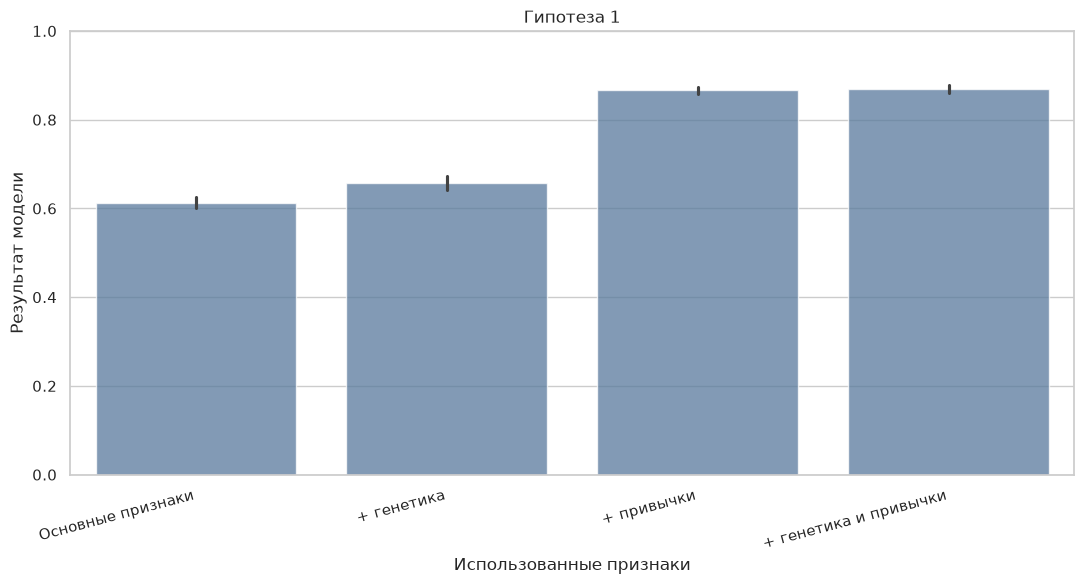

,mean
feature_set,
Основные признаки,0.613
+ генетика,0.659
+ привычки,0.866
+ генетика и привычки,0.869


Прирост от генетики: +0.045
Прирост от привычек: +0.253


In [27]:
demographic_features = ["Age", "Height", "Gender"]
genetic_proxy_features = ["family_history_with_overweight"]
habit_features = [
    "FAVC", "FCVC", "NCP", "CAEC", "SMOKE", "CH2O",
    "SCC", "FAF", "TUE", "CALC", "MTRANS",
]

def random_forest_for(feature_subset):
    numeric = [column for column in feature_subset if column in numeric_columns]
    categorical = [column for column in feature_subset if column in categorical_columns]
    subset_preprocessor = ColumnTransformer(
        [("numeric", numeric_preprocessor, numeric),
         ("categorical", categorical_preprocessor, categorical)]
    )
    return Pipeline([
        ("preprocessor", subset_preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300, random_state=random_state, n_jobs=-1
        )),
    ])

feature_sets = {
    "Основные признаки": demographic_features,
    "+ генетика": demographic_features + genetic_proxy_features,
    "+ привычки": demographic_features + habit_features,
    "+ генетика и привычки": (
        demographic_features + genetic_proxy_features + habit_features
    ),
}

group_scores = []
for feature_set_name, feature_subset in feature_sets.items():
    fold_scores = cross_validate(
        random_forest_for(feature_subset),
        X_train[feature_subset], y_train,
        cv=cross_validation, scoring="f1_macro", n_jobs=-1,
    )["test_score"]
    group_scores.extend(
        {"feature_set": feature_set_name, "fold": fold + 1, "macro_f1": score}
        for fold, score in enumerate(fold_scores)
    )

group_scores = pd.DataFrame(group_scores)
group_summary = group_scores.groupby("feature_set")["macro_f1"].agg(["mean"])
order = list(feature_sets)

plt.figure(figsize=(11, 6))
sns.barplot(data=group_scores, x="feature_set", y="macro_f1", order=order, color="#4C78A8", alpha=0.75)
plt.title("Гипотеза 1")
plt.xlabel("Использованные признаки")
plt.ylabel("Результат модели")
plt.xticks(rotation=15, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

family_gain = (group_summary.loc["+ генетика", "mean"]
               - group_summary.loc["Основные признаки", "mean"])
habit_gain = (group_summary.loc["+ привычки", "mean"]
              - group_summary.loc["Основные признаки", "mean"])
display(group_summary.loc[order].round(3))
print(f"Прирост от генетики: {family_gain:+.3f}")
print(f"Прирост от привычек: {habit_gain:+.3f}")

In [24]:
models_for_hypothesis_2 = {
    "logistic_regression": models["logistic_regression"],
    "decision_tree": models["decision_tree"],
    "random_forest": models["random_forest"],
}

model_fold_scores = []
for model_name, model in models_for_hypothesis_2.items():
    fold_scores = cross_validate(
        model, X_train, y_train, cv=cross_validation,
        scoring="f1_macro", n_jobs=-1,
    )["test_score"]
    model_fold_scores.extend(
        {"model": model_name, "fold": fold + 1, "macro_f1": score}
        for fold, score in enumerate(fold_scores)
    )

model_fold_scores = pd.DataFrame(model_fold_scores)
mean_model_scores = model_fold_scores.groupby("model")["macro_f1"].mean().sort_values()
display(mean_model_scores.to_frame("mean_cv_macro_f1").round(3))

,mean_cv_macro_f1
model,
logistic_regression,0.868
decision_tree,0.922
random_forest,0.930


In [25]:
class_order = sorted(y_test.unique())
class_diagnostics = pd.DataFrame({
    "support": y_test.value_counts(),
    "recall": test_report.loc[class_order, "recall"],
}).loc[class_order]
support_recall_rho = class_diagnostics["support"].corr(
    class_diagnostics["recall"], method="spearman"
)

display(class_diagnostics.sort_values("support").round(3))

,support,recall
Insufficient_Weight,54,0.944
Normal_Weight,58,0.914
Overweight_Level_II,58,0.931
Overweight_Level_I,58,0.845
Obesity_Type_II,60,0.983
Obesity_Type_III,65,0.985
Obesity_Type_I,70,0.957
